# 01 – Exploration: Who Gets Into Financial Trouble?

> **Project notebooks:** [01 Exploration](01_exploration.ipynb) · [02 First model](02_first_model.ipynb) · [03 Tuning and blending](03_tuning_and_blending.ipynb) · [04 Calibration](04_calibration.ipynb) · [05 Explanation and fairness](05_explanation_and_fairness.ipynb)

**Goal of the project:** predict which borrowers will get into serious financial trouble within the next two years, so that a bank can decide whom to lend to. This is called **credit scoring**, and it is one of the oldest and most important uses of prediction in business.

**Data:** [Kaggle – Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit/data) (`cs-training.csv`, 150,000 borrowers).

**Lessons from the loan project:** before trusting any pattern, we check the data for copies and other traps, because in [the loan default project](https://github.com/OlgaKoleda/loan-default-prediction) a dataset that looked clean turned out to be 86% copies.

**Contents**
1. Load and inspect the data
2. The target: a rare event
3. Sanity checks: copies and missing values
4. Strange values: codes, outliers and a column with two meanings
5. What predicts trouble?
6. Summary and cleaning decisions

## 1. Load and inspect the data

In [1]:
import sys
sys.path.append("..")   # the project folder, where src/ lives

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from src.features import load, TARGET, LATE_COLUMNS

warnings.filterwarnings("ignore", category=FutureWarning)  # hide a harmless seaborn/pandas version notice
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

df = load("../data/cs-training.csv")
print(f"Rows: {len(df):,}, columns: {df.shape[1]}")
df.head()

Rows: 150,000, columns: 12


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


The first column has no name in the file, so `load()` in [`src/features.py`](../src/features.py) names it `Id`.

The data dictionary (`data/Data Dictionary.xls`) describes the columns:

| Column | Meaning |
|---|---|
| `SeriousDlqin2yrs` | **target**: 1 = was 90 days or more late with a payment within the next two years |
| `RevolvingUtilizationOfUnsecuredLines` | credit card and personal credit line balances divided by their limits ("how much of the available credit is used") |
| `age` | age in years |
| `NumberOfTime30-59DaysPastDueNotWorse` | times 30–59 days late with a payment in the last two years |
| `NumberOfTime60-89DaysPastDueNotWorse` | times 60–89 days late |
| `NumberOfTimes90DaysLate` | times 90 days or more late |
| `DebtRatio` | monthly debt payments, alimony and living costs divided by monthly income |
| `MonthlyIncome` | monthly income |
| `NumberOfOpenCreditLinesAndLoans` | open loans (car, mortgage) and credit lines (credit cards) |
| `NumberRealEstateLoansOrLines` | mortgages and other real estate loans |
| `NumberOfDependents` | family members the borrower supports |

Unlike the house price data, every column here is a number, and unlike the loan data, the columns describe **credit behaviour** (how the person has handled debt so far), not just who they are. That should make prediction much easier.

In [2]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Id,150000.0,75000.50,43301.41,1.0,37500.75,75000.50,112500.25,150000.0
SeriousDlqin2yrs,150000.0,0.07,0.25,0.0,0.00,0.00,0.00,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.03,0.15,0.56,50708.0
age,150000.0,52.30,14.77,0.0,41.00,52.00,63.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.00,0.00,0.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.18,0.37,0.87,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,3400.00,5400.00,8249.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.00,0.00,0.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0


Several maximum values are impossible: someone who used **50,708 times** their credit limit, a debt ratio of **329,664**, a monthly income of **3 million**, and late‑payment counts of **98** within two years (there are only 24 months). We will investigate these in section 4.

## 2. The target: a rare event

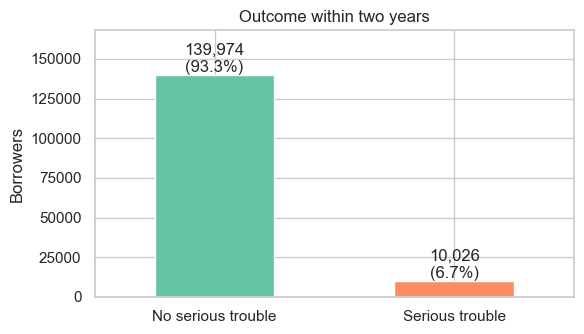

Share in serious trouble: 6.68%
Accuracy of a 'model' that says nobody will: 93.32%


In [3]:
default_rate = df[TARGET].mean()

fig, ax = plt.subplots(figsize=(6, 3.5))
counts = df[TARGET].map({0: "No serious trouble", 1: "Serious trouble"}).value_counts()
counts.plot.bar(ax=ax, color=["C0", "C1"])
for i, value in enumerate(counts):
    ax.text(i, value, f"{value:,}\n({value / len(df):.1%})", ha="center", va="bottom")
ax.set(title="Outcome within two years", ylabel="Borrowers", xlabel="")
ax.set_ylim(0, counts.max() * 1.2)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(f"Share in serious trouble: {default_rate:.2%}")
print(f"Accuracy of a 'model' that says nobody will: {1 - default_rate:.2%}")

Only **6.7%** of the borrowers got into serious trouble: about 1 in 15. The class is even more imbalanced than in the loan project (12.3%), so the accuracy trap is even bigger: predicting "nobody" is 93.3% accurate and useless. We will again use ROC AUC and average precision, and Kaggle scores this competition with **ROC AUC**.

For simplicity we call these borrowers **"defaulters"** from here on.

## 3. Sanity checks: copies and missing values

First the check that exposed the loan dataset: are there identical rows?

In [4]:
features = [c for c in df.columns if c not in ("Id", TARGET)]
duplicated = df.duplicated(subset=features, keep=False)

print(f"Rows with an identical twin: {duplicated.sum():,} ({duplicated.mean():.1%})")
print(f"Of those, rows with a missing income: {df.loc[duplicated, 'MonthlyIncome'].isna().mean():.0%}")
df.loc[duplicated, features].head(4)

Rows with an identical twin: 1,000 (0.7%)
Of those, rows with a missing income: 85%


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
52,1.0,62,0,0.0,NaN,1,0,0,0,0.0
331,1.0,29,0,0.0,NaN,0,0,0,0,0.0
530,0.0,82,0,0.0,NaN,3,0,0,0,0.0
1250,0.0,84,0,0.0,NaN,1,0,0,0,0.0


Only **0.7%** of rows have a twin, and they look like what you would expect by coincidence: simple profiles with mostly zeros (no late payments, no debt, one or no credit line) and a missing income. With 150,000 people, some will share such a simple profile. This is nothing like the loan data, where 86% of rows were copies spread through the file in a regular pattern.

**Verdict:** no sign of artificial copies. We can use an ordinary random split for evaluation.

Next, missing values:

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0]
print((missing / len(df)).map("{:.1%}".format).to_string())

both = (df["MonthlyIncome"].isna() & df["NumberOfDependents"].isna()).sum()
print(f"\nBorrowers with missing dependents who also have a missing income: {both:,} of {missing['NumberOfDependents']:,}")

income_missing = df["MonthlyIncome"].isna()
print(f"\nDefault rate, income known:   {df.loc[~income_missing, TARGET].mean():.1%}")
print(f"Default rate, income missing: {df.loc[income_missing, TARGET].mean():.1%}")

MonthlyIncome         19.8%
NumberOfDependents     2.6%

Borrowers with missing dependents who also have a missing income: 3,924 of 3,924

Default rate, income known:   6.9%
Default rate, income missing: 5.6%


- **Income is missing for 20%** of borrowers, and every borrower with a missing number of dependents also has a missing income. These gaps probably come from the same incomplete applications.
- Borrowers with a missing income default **less** often (5.6% vs. 6.9%). Whatever the reason, *the gap itself carries information*. If we simply filled it with the median income, that information would be lost. So the model should get a yes/no column "income missing".

## 4. Strange values: codes, outliers and a column with two meanings

### Late payments: 96 and 98 are not counts

In [6]:
for column in LATE_COLUMNS:
    print(f"{column}: highest values {sorted(df[column].unique())[-5:]}")

special = (df[LATE_COLUMNS] >= 96).any(axis=1)
print(f"\nBorrowers with 96 or 98: {special.sum()}, and it appears in all three columns at once: "
      f"{(df.loc[special, LATE_COLUMNS] >= 96).all(axis=1).all()}")
df.loc[special, features].describe().loc[["mean", "50%"]].round(2)

NumberOfTime30-59DaysPastDueNotWorse: highest values [11, 12, 13, 96, 98]
NumberOfTime60-89DaysPastDueNotWorse: highest values [8, 9, 11, 96, 98]
NumberOfTimes90DaysLate: highest values [14, 15, 17, 96, 98]

Borrowers with 96 or 98: 269, and it appears in all three columns at once: True


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
mean,1.0,34.25,97.96,5.74,2557.14,0.01,97.96,0.0,97.96,0.37
50%,1.0,29.00,98.00,0.00,2168.50,0.00,98.00,0.0,98.00,0.00


The counts go up to about 17, then jump to **96 and 98**. Being late 98 times in 24 months is impossible. These 269 borrowers have 96 or 98 in all three late‑payment columns at the same time, and look very different from everyone else: no open credit lines at all, a utilisation of exactly 1.0, and a median age of 29.

**96 and 98 are codes**, probably meaning something like "no data" or "no credit history". If we left them as numbers, a linear model would treat these borrowers as the latest payers ever by a huge margin. The fix: replace the codes by 0 and add a separate yes/no column `NoCreditHistoryCode`.

### Credit utilisation: values above 1

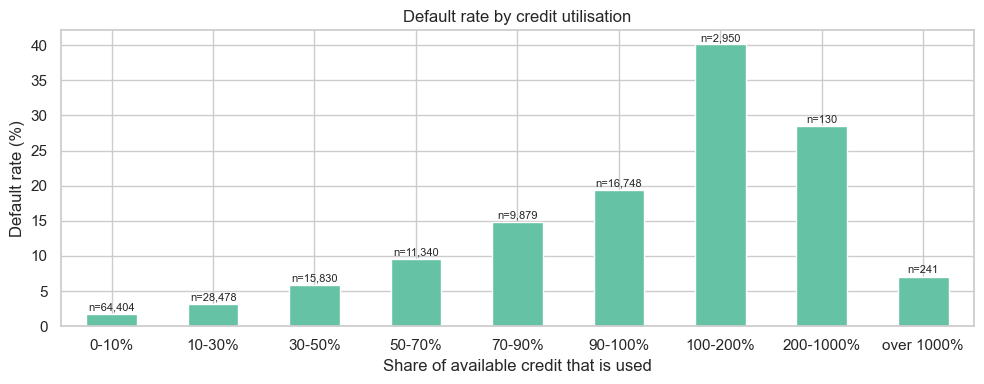

In [7]:
utilisation = df["RevolvingUtilizationOfUnsecuredLines"]
bands = pd.cut(utilisation, [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 2, 10, utilisation.max()],
               labels=["0-10%", "10-30%", "30-50%", "50-70%", "70-90%", "90-100%", "100-200%", "200-1000%", "over 1000%"])
table = df.groupby(bands, observed=True)[TARGET].agg(default_rate="mean", borrowers="size")

fig, ax = plt.subplots(figsize=(10, 4))
(table["default_rate"] * 100).plot.bar(ax=ax, color="C0")
for i, n in enumerate(table["borrowers"]):
    ax.text(i, table["default_rate"].iloc[i] * 100 + 0.5, f"n={n:,}", ha="center", fontsize=8)
ax.set(title="Default rate by credit utilisation", xlabel="Share of available credit that is used", ylabel="Default rate (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../images/default_by_utilisation.png", dpi=120)
plt.show()

A beautiful pattern up to 200%: the more of their credit people use, the more likely they get into trouble, from **2%** for those using under 10% to **40%** for those over their limit. Using more than 100% is possible: it means being over the credit limit.

Then the pattern breaks. The 241 borrowers with a utilisation **over 1,000%** default at only about 7%, the average rate. Values like 50,708 times the limit are almost certainly **data errors** (perhaps an amount entered where a ratio was expected). We cap the column at 10: large enough to keep the real "over the limit" signal, small enough that a few absurd values cannot dominate a linear model.

### Debt ratio: one column, two meanings

In [8]:
print(f"Median DebtRatio when income is known:   {df.loc[~income_missing, 'DebtRatio'].median():.2f}")
print(f"Median DebtRatio when income is missing: {df.loc[income_missing, 'DebtRatio'].median():,.0f}")
print(f"\nDebtRatio above 1 when income is known:   {(df.loc[~income_missing, 'DebtRatio'] > 1).mean():.0%}")
print(f"DebtRatio above 1 when income is missing: {(df.loc[income_missing, 'DebtRatio'] > 1).mean():.0%}")

Median DebtRatio when income is known:   0.30
Median DebtRatio when income is missing: 1,159

DebtRatio above 1 when income is known:   6%
DebtRatio above 1 when income is missing: 94%


This is a subtle problem, and a typical one in real data. When the income is known, `DebtRatio` is a ratio, as the dictionary says: a typical borrower spends about 30% of their income on debt. When the income is **missing**, the "ratio" is typically **1,159**. The system could not divide by a missing income, so it apparently stored the **monthly debt amount in dollars** instead.

The column therefore mixes two different quantities, and a model cannot tell them apart. The fix is to split it: `DebtRatio` keeps only real ratios (and is empty when the income is missing), and a new column `MonthlyDebtWhenIncomeUnknown` keeps the dollar amounts.

**Lesson:** a column can follow the data dictionary for most rows and mean something completely different for others. Comparing a column's values *across groups*, here with and without income, is how you find out.

## 5. What predicts trouble?

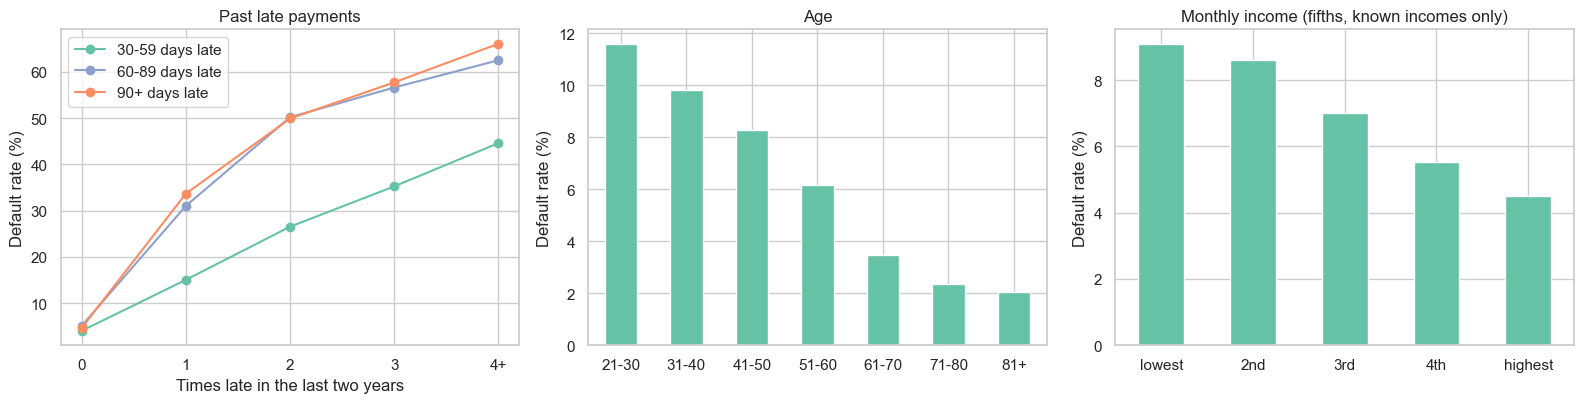

Default rate, never late in the last two years: 2.8% (80% of borrowers)
Default rate, late at least once:               22.0% (20% of borrowers)


In [9]:
late_counts = df[LATE_COLUMNS].where(~special)        # leave out the 96/98 codes
ever_late = late_counts.sum(axis=1) > 0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for column, label, color in zip(LATE_COLUMNS, ["30-59 days late", "60-89 days late", "90+ days late"], ["C0", "C2", "C1"]):
    rates = df.groupby(late_counts[column].clip(upper=4))[TARGET].mean() * 100
    axes[0].plot(rates.index, rates.values, marker="o", label=label, color=color)
axes[0].set_xticks(range(5), ["0", "1", "2", "3", "4+"])
axes[0].set(title="Past late payments", xlabel="Times late in the last two years", ylabel="Default rate (%)")
axes[0].legend()

age_rates = df.groupby(pd.cut(df["age"], [20, 30, 40, 50, 60, 70, 80, 110],
                              labels=["21-30", "31-40", "41-50", "51-60", "61-70", "71-80", "81+"]), observed=True)[TARGET].mean() * 100
age_rates.plot.bar(ax=axes[1], color="C0")
axes[1].set(title="Age", xlabel="", ylabel="Default rate (%)")
axes[1].tick_params(axis="x", rotation=0)

income_rates = df.groupby(pd.qcut(df["MonthlyIncome"], 5, labels=["lowest", "2nd", "3rd", "4th", "highest"]),
                          observed=True)[TARGET].mean() * 100
income_rates.plot.bar(ax=axes[2], color="C0")
axes[2].set(title="Monthly income (fifths, known incomes only)", xlabel="", ylabel="Default rate (%)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("../images/default_drivers.png", dpi=120)
plt.show()

print(f"Default rate, never late in the last two years: {df.loc[~ever_late, TARGET].mean():.1%} ({(~ever_late).mean():.0%} of borrowers)")
print(f"Default rate, late at least once:               {df.loc[ever_late, TARGET].mean():.1%} ({ever_late.mean():.0%} of borrowers)")

Now we see real, strong patterns, very different from the loan data:

- **Past behaviour predicts future behaviour.** Borrowers who were never late in the last two years default at **2.8%**; those who were late at least once at **22%**, eight times more often. Each additional late payment raises the risk further, and being 60 or 90 days late is worse than being 30 days late.
- **Age:** the risk falls steadily with age, from about 12% for borrowers in their twenties to about 2% for those over 70.
- **Income:** a higher income means lower risk, but the effect is modest: from 9% in the lowest fifth to 4.5% in the highest.

These patterns make sense to anyone who has thought about money. That is a good sign: a credit model built on them will be easier to trust and to explain.

## 6. Summary and cleaning decisions

| Question | Answer |
|---|---|
| Target? | Rare: 6.7% got into serious trouble. Kaggle scores with ROC AUC. |
| Copies? | Only 0.7%, by coincidence. A random split is fine. |
| Missing values? | Income 20% (and dependents 2.6%, always together with income). The gap itself is informative. |
| Strongest signal? | Past late payments: 2.8% vs. 22% default rate. Then credit utilisation and age. |

**Problems and decisions**, all implemented in `CreditFeatures` in [`src/features.py`](../src/features.py):

| Problem | Decision |
|---|---|
| Late‑payment counts 96 and 98 are codes | replace with 0, add a `NoCreditHistoryCode` flag |
| Utilisation values up to 50,708 | cap at 10 |
| `DebtRatio` is a dollar amount when income is missing | split into `DebtRatio` (true ratios only) and `MonthlyDebtWhenIncomeUnknown` |
| Income missing for 20% | add an `IncomeMissing` flag |
| One borrower aged 0 | treat as 18 |
| New feature | `TimesLate`: all late payments added up |

**Next:** in [02_first_model](02_first_model.ipynb) we build a first model, test whether this cleaning helps, and learn how to turn a risk score into a lending decision.